# Credit-risk: данные → эксперимент → объяснение

Воспроизводимая демонстрация классификации **искусственной метки**, не наблюдаемого дефолта. Точное правило уже известно; ML нужен здесь для изучения pipeline и оценки, а не для замены правила. Перед запуском установите пакет и dev-зависимости по README. Исторический эксперимент сохранён в корневом `Credit risk.ipynb`.

In [1]:
from pathlib import Path
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from credit_risk.data import normalize_features, synthetic_target
from credit_risk.model import fit_experiment, predict_frame, explain_one

ROOT = Path.cwd()
if not (ROOT / "credit.csv").exists():
    ROOT = ROOT.parent
raw = pd.read_csv(ROOT / "credit.csv")
X = normalize_features(raw)
y = synthetic_target(X)
print(f"Rows: {len(raw)}, synthetic positives: {int(y.sum())}")
raw.head()

Rows: 1000, synthetic positives: 13


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,0,67,male,2,own,NaN,little,1169,6,radio/TV
1,1,22,female,2,own,little,moderate,5951,48,radio/TV
2,2,49,male,1,own,little,NaN,2096,12,education
3,3,45,male,2,free,little,little,7882,42,furniture/equipment
4,4,53,male,2,free,little,little,4870,24,car


## 1. Данные и пропуски

Индексный столбец и `Sex` не входят в модель. Пол исключён из предикторов; это не доказывает справедливость модели, возраст и другие признаки могут сохранять зависимости. Единицы денежных сумм и первоисточник CSV ещё не подтверждены.

In [2]:
summary = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "unique": raw.nunique()})
summary

,dtype,missing,unique
Unnamed: 0,int64,0,1000
Age,int64,0,53
Sex,object,0,2
Job,int64,0,4
Housing,object,0,3
Saving accounts,object,183,4
Checking account,object,394,3
Credit amount,int64,0,921
Duration,int64,0,33
Purpose,object,0,8


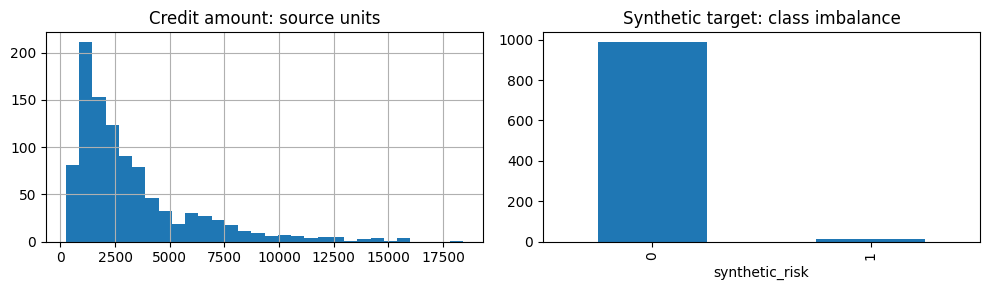

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
raw["Credit amount"].hist(bins=30, ax=axes[0])
axes[0].set_title("Credit amount: source units")
y.value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set_title("Synthetic target: class imbalance")
fig.tight_layout()
plt.show()

## 2. SQL-анализ без расширений и магических команд

Временная SQLite-база создаётся в памяти. Запросы демонстрируют агрегации, NULL, подзапрос, CTE и оконные функции; стабильная сортировка делает результаты удобными для повторного показа.

In [4]:
conn = sqlite3.connect(":memory:")
raw.to_sql("credit_data", conn, index=False, if_exists="replace")
queries = {
    "Amounts by purpose": """SELECT Purpose, COUNT(*) AS records,
        ROUND(AVG("Credit amount"), 2) AS mean_amount,
        ROUND(AVG(Duration), 2) AS mean_duration
        FROM credit_data GROUP BY Purpose ORDER BY records DESC, Purpose""",
    "Non-missing accounts": """SELECT COUNT("Saving accounts") AS known,
        COUNT(*) AS total,
        ROUND(100.0 * COUNT("Saving accounts") / COUNT(*), 2) AS percent_known
        FROM credit_data""",
    "Above purpose average": """SELECT Purpose, "Credit amount", Duration
        FROM credit_data cd WHERE "Credit amount" > (
        SELECT AVG("Credit amount") FROM credit_data WHERE Purpose = cd.Purpose)
        ORDER BY "Credit amount" DESC, Duration DESC, Purpose LIMIT 10""",
    "Most common purpose per age group": """WITH age_groups AS (
        SELECT CASE WHEN Age < 30 THEN '<30' WHEN Age <= 50 THEN '30-50'
        ELSE '>50' END AS age_group, Purpose, COUNT(*) AS n
        FROM credit_data GROUP BY 1, 2), ranked AS (
        SELECT *, ROW_NUMBER() OVER (PARTITION BY age_group ORDER BY n DESC, Purpose) AS rn
        FROM age_groups)
        SELECT age_group, Purpose, n FROM ranked WHERE rn = 1 ORDER BY age_group""",
}
for title, query in queries.items():
    print("\n" + title)
    display(pd.read_sql_query(query, conn))
conn.close()


Amounts by purpose


,Purpose,records,mean_amount,mean_duration
0,car,337,3768.19,20.81
1,radio/TV,280,2487.65,20.05
2,furniture/equipment,181,3066.99,19.29
3,business,97,4158.04,26.94
4,education,59,2879.20,19.68
5,repairs,22,2728.09,19.09
6,domestic appliances,12,1498.00,16.83
7,vacation/others,12,8209.33,32.33



Non-missing accounts


,known,total,percent_known
0,817,1000,81.7



Above purpose average


,Purpose,Credit amount,Duration
0,vacation/others,18424,48
1,business,15945,54
2,vacation/others,15857,36
3,business,15672,48
4,radio/TV,15653,60
5,car,14896,6
6,vacation/others,14782,60
7,car,14555,6
8,business,14421,48
9,car,14318,36



Most common purpose per age group


,age_group,Purpose,n
0,30-50,car,192
1,<30,radio/TV,117
2,>50,car,43


## 3. Train / validation / test

60/20/20, stratified, seed=42. Преобразования обучаются только на train. Порог выбирается по F1 на validation; test используется для итогового отчёта. При малом количестве положительных примеров метрики нестабильны. Точное правило даёт идеальное совпадение с меткой по определению.

In [5]:
bundle, report, heldout = fit_experiment(raw)
print(json.dumps({"splits": report["splits"], "threshold": report["threshold"]}, indent=2))
pd.DataFrame(report["test"]).T[["roc_auc", "average_precision", "precision", "recall", "f1", "accuracy"]]

{
  "splits": {
    "train": {
      "rows": 600,
      "positives": 8,
      "negatives": 592
    },
    "validation": {
      "rows": 200,
      "positives": 2,
      "negatives": 198
    },
    "test": {
      "rows": 200,
      "positives": 3,
      "negatives": 197
    }
  },
  "threshold": 0.55
}


,roc_auc,average_precision,precision,recall,f1,accuracy
logistic_regression,0.994924,0.833333,0.5,0.666667,0.571429,0.985
majority_baseline,0.5,0.015,0.0,0.0,0.0,0.985
label_rule_reference,1.0,1.0,1.0,1.0,1.0,1.0


## 4. Предсказание и линейное объяснение

CLI, Streamlit и этот ноутбук используют одинаковый код. Вклад считается после преобразования признаков. Полная сумма вкладов + baseline равна log-odds модели; это не причинное объяснение и не SHAP.

In [6]:
row = raw.iloc[[17]]
prediction = predict_frame(bundle, row)
baseline, contributions = explain_one(bundle, row)
log_odds = bundle["pipeline"].decision_function(normalize_features(row))[0]
assert np.isclose(baseline + contributions["log_odds_contribution"].sum(), log_odds)
print(prediction.to_string(index=False))
contributions.head(10)

   score  predicted_class display_band  rule_label
0.631079                1            C           1


,feature,log_odds_contribution
0,numeric__Credit amount,3.540436
1,categorical__Checking account_little,2.680205
2,numeric__Age,0.769671
3,categorical__Purpose_business,-0.634827
4,categorical__Purpose_car,-0.611036
5,categorical__Checking account_missing,0.610122
6,categorical__Checking account_moderate,0.592159
7,categorical__Saving accounts_missing,0.350148
8,numeric__Duration,0.296435
9,categorical__Purpose_radio/TV,0.263328


## 5. Вывод

Проект демонстрирует воспроизводимый инженерный цикл. Его ограничивает искусственная целевая метка и очень малое число положительных примеров. Следующий исследовательский шаг — отдельный эксперимент с наблюдаемым исходом и подтверждённым источником данных. Числа из этого ноутбука не являются качеством реального кредитного скоринга.